# 03 · Improved surrogates: fixing what the paper's Random Forest gets wrong

Notebook 02 showed the paper's model scores well on a linear scale but loses the off-state completely.
Here we compare six models on **the same dataset 4 split**, using the paper's metrics plus device metrics
(I_ON, I_OFF, V_th, SS), then stress-test them: fine $V_G$ grids, extrapolation and small training sets.

**Honest note:** all data comes from our analytical simulator (`tfet/physics.py`), not TCAD. It is a smooth formula,
so it is easier to learn than real TCAD data. Scores here do not prove the same accuracy on TCAD data.

### 🧒 This notebook in simple words
In notebook 2 the paper's guesser looked great, but it could not see tiny currents at all. Imagine a bathroom scale that
weighs people well but says "1 kg" for every coin, feather and grain of rice. Tiny currents matter here, because a
switch's quality depends on how little it leaks when it is **off**.

Our main fix is simple: **stop guessing the current, and guess how many zeros it has** (its logarithm).
Then 0.000000001 and 0.00000000001 look clearly different to the model.

We then try several guessers and check which fix actually helps.

**Words you need for this notebook:**

| Word | Simple meaning |
|---|---|
| **log10 target** | the model guesses the "number of zeros" of the current, not the current itself |
| **Decade** | a factor of 10 in current. 1e-9 to 1e-8 is one decade |
| **XGBoost** | a set of small trees built one after another, each fixing the mistakes of the last |
| **MLP / neural network** | a stack of simple maths layers that learns a *smooth* curve (trees learn steps) |
| **Physics features** | extra inputs worked out from known formulas: tunnelling length λ and tunnelling area A_tun |
| **Monotonicity penalty** | a training rule: "current must rise with $V_G$". The model is marked down if it doesn't |
| **PI-MLP** | physics-informed MLP: physics features **and** the monotonicity penalty |
| **Ablation** | switching on one idea at a time to see which one really helped |
| **Seed** | the starting random number. We train with 3 seeds so one lucky run can't fool us |
| **Noise floor** | our data has 0.5 % random noise, so no model can honestly score better than that |
| **Extrapolation** | guessing outside the range the model learned from |
| **FoM (figure of merit)** | a number describing the device: I_ON, I_OFF, V_th, SS |

### 🧰 Block: tools, data and the noise floor
**What it does:**
1. Loads libraries and dataset 4, and makes **exactly the same split as notebook 2** (`curve_split(ds4, 0.2)`, seed 42).
2. Sets `PYTHONPATH` so the parallel workers can find our `tfet` package.
3. Works out the **noise floor**: it compares the noisy test data with the clean simulator output.

**How to read it:** the printed dictionary is the score of a *perfect* model that knows the true physics. It is the best
anyone can do on this data.

**What to notice:** the median relative error of a perfect model is about 0.34 %, not 0 %. Any model near that
value has nothing left to learn.

In [1]:
# --- tools, data, noise floor ---
import os, sys, time
sys.path.append("..")
os.environ["PYTHONPATH"] = os.path.abspath("..")   # parallel workers need to find tfet
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import xgboost as xgb
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from tfet import NOMINAL, drain_current, id_vg
from tfet.metrics import subthreshold_swing
from tfet.evaluate import (FEATURES, curve_split, regression_report, error_by_decade,
                           fom_errors, monotonic_violations)
from tfet.surrogate import add_physics_features, train_run

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
ds4 = pd.read_pickle("../data/ds4_all_params.pkl")
train, test = curve_split(ds4, 0.2)
print("train curves:", train.curve_id.nunique(), "| test curves:", test.curve_id.nunique())

clean = drain_current(test.V_G.values, test.L_ov.values, test.WK.values, test.t_n.values, test.t_ox.values)
floor = regression_report(test.I_D, clean)
print("noise floor (perfect model):", {k: round(float(v), 3) for k, v in floor.items()})

train curves: 2000 | test curves: 500
noise floor (perfect model): {'R2_linear_%': 99.997, 'RMSE_%std': 0.505, 'R2_log10_%': 100.0, 'median_rel_err_%': 0.339, 'p95_rel_err_%': 0.979}


### 🌲 Block: the four tree models
**What it does:** defines and trains four tree guessers, and times how long each takes to learn and to predict.
* **RFR-linear:** the paper's model, 100 trees, guesses the current directly.
* **RFR-log:** the same forest, but it guesses log10 of the current. This is the only change, so it isolates the log idea.
* **XGB-log:** XGBoost guessing log10 of the current.
* **XGB-log+feat:** the same, with λ and A_tun as extra inputs.

`score()` is our one marking scheme. It gives every model the same exam.

**How to read it:** nothing to look at yet. The table comes a few blocks later.

In [2]:
# --- four tree models + one marking scheme for everybody ---
def X_of(df, physics=False):
    X = df[FEATURES].values
    return add_physics_features(X, FEATURES)[0] if physics else X

def make_rfr():
    return make_pipeline(StandardScaler(), RandomForestRegressor(
        n_estimators=100, max_depth=None, criterion="squared_error", random_state=42, n_jobs=-1))

def make_xgb():
    return xgb.XGBRegressor(n_estimators=600, max_depth=8, learning_rate=0.05, subsample=0.8,
                            tree_method="hist", n_jobs=8, random_state=42)

TREES = {  # name: (builder, uses log target?, uses physics features?)
    "RFR-linear (paper)": (make_rfr, False, False),
    "RFR-log":            (make_rfr, True,  False),
    "XGB-log":            (make_xgb, True,  False),
    "XGB-log+feat":       (make_xgb, True,  True),
}

def fit_tree(name, tr, te):
    build, log, phys = TREES[name]
    t0 = time.perf_counter()
    model = build().fit(X_of(tr, phys), np.log10(tr.I_D) if log else tr.I_D)
    t1 = time.perf_counter()
    p = model.predict(X_of(te, phys))
    t2 = time.perf_counter()
    return (10 ** p if log else p), t1 - t0, t2 - t1

def score(te, pred, train_s=np.nan, infer_s=np.nan):
    """The same exam for every model: paper metrics, device metrics, physics check, timing."""
    t = te.assign(I_pred=np.clip(pred, 1e-30, 1e3))
    return {**regression_report(t.I_D, t.I_pred), **fom_errors(t),
            "non_monotonic_%": monotonic_violations(t), "train_s": train_s, "infer_s": infer_s}

tree_pred, rows = {}, {}
for name in TREES:
    tree_pred[name], ts, tp = fit_tree(name, train, test)
    rows[name] = score(test, tree_pred[name], ts, tp)
    print(f"{name:22s} train {ts:6.1f} s")

RFR-linear (paper)     train    3.1 s


RFR-log                train    3.0 s


XGB-log                train    1.8 s


XGB-log+feat           train    1.6 s


### 🧠 Block: the three neural networks (the ablation)
**What it does:** trains three MLPs, each with **3 seeds**, four at a time on the CPU:
* **MLP-log:** log10 target only.
* **MLP-log+feat:** adds the physics features λ and A_tun.
* **PI-MLP:** adds the features **and** the monotonicity penalty.

Each run gets the same budget of 5000 training steps. Going one idea at a time is the **ablation**: if the score moves, we
know which idea moved it.

**How to read it:** each line shows one run. `train_s` is the time for one run while others share the CPU, so it is
slower than a run alone.

In [3]:
# --- three MLP variants x 3 seeds, 4 trainings at a time ---
VARIANTS = {  # name: (physics features?, weight of the monotonicity penalty)
    "MLP-log":      (False, 0.0),
    "MLP-log+feat": (True,  0.0),
    "PI-MLP":       (True,  1.0),
}
SEEDS = (0, 1, 2)

def run_grid(tr, te, steps, variants=VARIANTS, seeds=SEEDS):
    """Train every (variant, seed) pair; return {(variant, seed): (model, predictions, seconds)}."""
    jobs = [(v, s) for v in variants for s in seeds]
    A = (X_of(tr), tr.I_D.values, X_of(te), FEATURES)
    out = Parallel(n_jobs=4)(delayed(train_run)(*A, physics=variants[v][0], mono_weight=variants[v][1],
                                                seed=s, steps=steps) for v, s in jobs)
    return dict(zip(jobs, out))

t0 = time.perf_counter()
runs = run_grid(train, test, steps=5000)
print(f"all {len(runs)} trainings took {(time.perf_counter() - t0) / 60:.1f} min")
for (v, s), (_, _, sec) in runs.items():
    print(f"{v:14s} seed {s}  train_s {sec:6.1f}")

all 9 trainings took 7.6 min
MLP-log        seed 0  train_s  163.6
MLP-log        seed 1  train_s  176.5
MLP-log        seed 2  train_s  158.2
MLP-log+feat   seed 0  train_s  161.8
MLP-log+feat   seed 1  train_s  167.0
MLP-log+feat   seed 2  train_s  165.5
PI-MLP         seed 0  train_s  240.5
PI-MLP         seed 1  train_s  232.7
PI-MLP         seed 2  train_s  129.2


### 🏆 Block: the big comparison table
**What it does:** gives every model the same exam on the 500 unseen curves. For the MLPs, it shows the **average of 3 seeds**.
The second table shows how much the MLP scores moved between seeds.

**How to read it:**
* `R2_linear_%` is the paper's score. `R2_log10_%` is the score that also cares about tiny currents.
* `median_rel_err_%`: the typical mistake as a percentage. Compare it with the noise floor.
* `I_off_err_decades`: how many factors of 10 the leakage is wrong by.
* `V_th_missing_%`: how often we couldn't get a V_th from the predicted curve at all.
* `non_monotonic_%`: how many predicted curves wrongly go down somewhere.

**What to notice:** see the summary under the table.

In [4]:
# --- one table, same exam for every model ---
torch.set_num_threads(8)
seed_scores = {}
for (v, s), (model, pred, sec) in runs.items():
    t0 = time.perf_counter(); model.predict(X_of(test)); tp = time.perf_counter() - t0
    seed_scores[(v, s)] = score(test, pred, sec, tp)
seed_df = pd.DataFrame(seed_scores).T
seed_df.index.names = ["model", "seed"]
for v in VARIANTS:
    rows[v] = seed_df.loc[v].mean().to_dict()
table = pd.DataFrame(rows).T
table.to_csv("../data/nb03_comparison.csv")
show = ["R2_linear_%", "R2_log10_%", "median_rel_err_%", "p95_rel_err_%", "I_on_err_%", "I_off_err_decades",
        "V_th_err_mV", "V_th_missing_%", "SS_min_err_mV/dec", "non_monotonic_%", "train_s", "infer_s"]
display(table[show].round(3).T)
print("spread between seeds (std over 3 seeds):")
display(seed_df.groupby("model")[["median_rel_err_%", "I_on_err_%", "I_off_err_decades", "V_th_err_mV",
                                  "SS_min_err_mV/dec"]].std().round(3))

,RFR-linear (paper),RFR-log,XGB-log,XGB-log+feat,MLP-log,MLP-log+feat,PI-MLP
R2_linear_%,93.253,91.026,96.720,96.201,99.745,99.951,99.955
R2_log10_%,63.717,99.262,99.731,99.859,99.995,99.998,99.998
median_rel_err_%,62.056,26.146,17.723,11.799,1.881,0.998,0.988
p95_rel_err_%,3856363.675,167.636,75.304,50.238,8.481,5.303,5.206
I_on_err_%,64.673,32.003,18.878,13.458,2.377,1.144,1.148
I_off_err_decades,3.337,0.162,0.105,0.068,0.024,0.017,0.016
V_th_err_mV,NaN,7.639,4.962,3.406,0.567,0.353,0.349
V_th_missing_%,77.400,1.000,1.000,0.400,0.200,0.000,0.000
SS_min_err_mV/dec,20.196,7.718,7.243,6.172,0.659,0.608,0.596
non_monotonic_%,24.200,20.000,18.200,5.600,0.000,0.067,0.067


spread between seeds (std over 3 seeds):


,median_rel_err_%,I_on_err_%,I_off_err_decades,V_th_err_mV,SS_min_err_mV/dec
model,,,,,
MLP-log,0.258,0.344,0.005,0.109,0.208
MLP-log+feat,0.088,0.042,0.006,0.130,0.171
PI-MLP,0.105,0.035,0.006,0.128,0.169


### 🔎 What the table shows
**The paper's model against our best one (500 unseen curves):**

| Check | RFR-linear (paper) | PI-MLP | Perfect model |
|---|---|---|---|
| Log-space $R^2$ | 63.7 % | 99.998 % | 100 % |
| Typical (median) error | 62 % | 0.99 % | 0.34 % |
| I_OFF error | 3.34 decades | 0.016 decades | |
| Curves with no usable V_th | 77.4 % | 0 % | |
| SS_min error | 20.2 mV/dec | 0.60 mV/dec | |
| Curves that wrongly go down | 24.2 % | 0.07 % | |

**Which idea actually helped?**
1. **The log target is the biggest single fix.** Changing only the target (RFR-linear to RFR-log) lifts log-space $R^2$ from 63.7 % to 99.3 % and cuts the I_OFF error from 3.34 to 0.16 decades. Its linear $R^2$ falls slightly, from 93.3 % to 91.0 %, which is why the paper's metric alone would have hidden this improvement.
2. **Smooth networks beat trees.** With the same log target, the typical error falls from 17.7 % (XGB-log) to 1.9 % (MLP-log).
3. **Physics features help, with a caveat.** They halve the MLP's error, from 1.88 % to 1.00 %, well beyond the seed spread. But λ and A_tun are formulas our simulator itself uses, so the model is being handed part of the answer. The gain may be smaller on real TCAD data.
4. **The monotonicity penalty did not measurably help.** MLP-log+feat and PI-MLP score 1.00 % and 0.99 %, and the seeds move by about 0.1 %. The networks were already almost perfectly monotonic: one curve in 1500 goes down, for both variants, and MLP-log has none. We report this as a negative result.

**Time:** tree models train in about 3 s. MLPs took about 3 minutes each here, while sharing the CPU with other runs, so treat those times as rough. All models predict the 25,500 test points in under 0.1 s.

### 📉 Block: error at every current level
**What it does:** repeats notebook 2's error-per-decade plot, now for the paper's model, RFR-log, XGB-log and PI-MLP (seed 0).

**How to read it:** left = tiny currents (off-state), right = big currents (on-state). Lower is better, and the
y-axis is logarithmic, so each grid line is 10× the error. The dashed line is the noise floor.

**What to notice:** the paper's model is off by huge factors below about 1e-9 A/µm. The log-target trees stay near 10–40 % at every level,
and PI-MLP stays under about 4 % across the whole range, closest to the noise floor around 1e-6 A/µm.

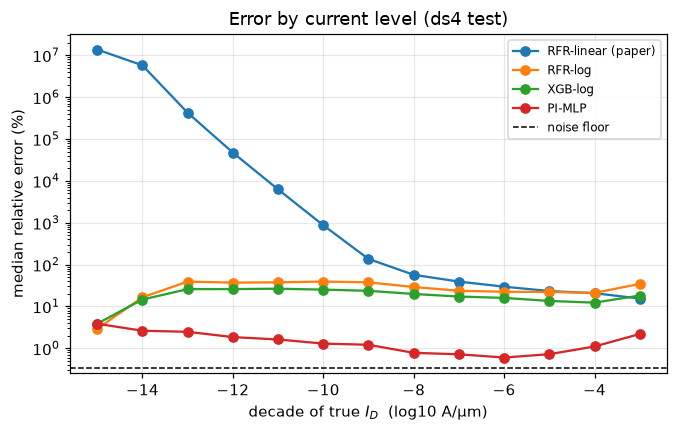

In [5]:
# --- error by decade ---
curves = {"RFR-linear (paper)": tree_pred["RFR-linear (paper)"], "RFR-log": tree_pred["RFR-log"],
          "XGB-log": tree_pred["XGB-log"], "PI-MLP": runs[("PI-MLP", 0)][1]}
fig, ax = plt.subplots(figsize=(7, 4))
for name, p in curves.items():
    d = error_by_decade(test.I_D, p)
    ax.semilogy(d.decade, d["median"], "o-", label=name)
ax.axhline(floor["median_rel_err_%"], color="k", ls="--", lw=1, label="noise floor")
ax.set(xlabel="decade of true $I_D$  (log10 A/µm)", ylabel="median relative error (%)",
       title="Error by current level (ds4 test)")
ax.legend(fontsize=8)
fig.savefig("../figures/03_error_by_decade.png", bbox_inches="tight")

### 🔬 Block: zoom in on one device (I_D, g_m and SS)
**What it does:** asks each model for the nominal device on a **10× finer** $V_G$ grid (501 points) than the training data,
then computes $g_m$ (how fast current rises) and SS (how sharply the switch turns on).

**How to read it:** black is the noise-free simulator. Left: the curve. Middle: $g_m$. Right: SS against $V_G$, lower = sharper.

**What to notice:** $g_m$ and SS use the **slope**, so they magnify any roughness. Both tree models are staircases: their $g_m$ is a row
of spikes, up to about 2000 µS/µm when the truth is about 240. Their SS barely appears on the right plot, because a flat step has
infinite SS. PI-MLP sits on the black line in all three plots. The printed check shows 0 for every model because flat steps
never actually go *down*, so that check can't detect a staircase. Only the plots show it.

non-monotonic steps on the fine grid: {'RFR-linear (paper)': 0, 'XGB-log': 0, 'PI-MLP': 0}


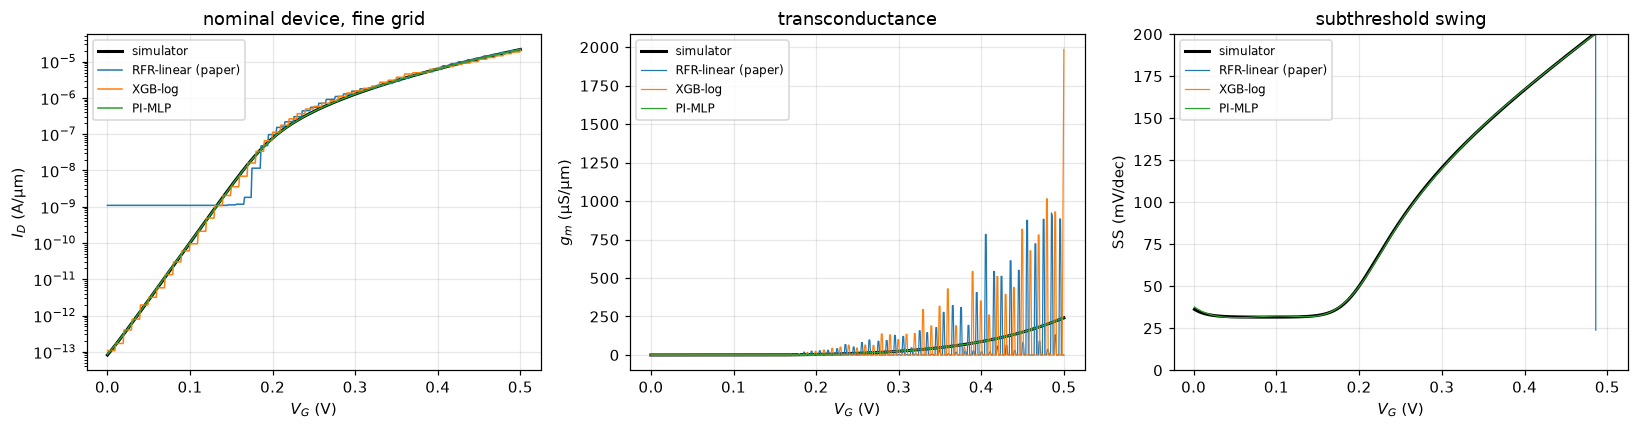

In [6]:
# --- fine grid: I_D, g_m, SS(V_G) on the nominal device ---
Vf = np.linspace(0, 0.5, 501)
_, If = id_vg(NOMINAL, V_G=Vf)
fine = pd.DataFrame({"V_G": Vf, **NOMINAL})
rfr = make_rfr().fit(X_of(train), train.I_D)
xg = make_xgb().fit(X_of(train), np.log10(train.I_D))
preds = {"RFR-linear (paper)": rfr.predict(X_of(fine)),
         "XGB-log": 10 ** xg.predict(X_of(fine)),
         "PI-MLP": runs[("PI-MLP", 0)][0].predict(X_of(fine))}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].semilogy(Vf, If, "k-", lw=2, label="simulator")
axes[1].plot(Vf, np.gradient(If, Vf) * 1e6, "k-", lw=2, label="simulator")
axes[2].plot(Vf[1:], subthreshold_swing(Vf, If), "k-", lw=2, label="simulator")
for name, p in preds.items():
    axes[0].semilogy(Vf, p, lw=1, label=name)
    axes[1].plot(Vf, np.gradient(p, Vf) * 1e6, lw=0.8, label=name)
    axes[2].plot(Vf[1:], subthreshold_swing(Vf, p), lw=0.8, label=name)
axes[0].set(xlabel="$V_G$ (V)", ylabel="$I_D$ (A/µm)", title="nominal device, fine grid")
axes[1].set(xlabel="$V_G$ (V)", ylabel="$g_m$ (µS/µm)", title="transconductance")
axes[2].set(xlabel="$V_G$ (V)", ylabel="SS (mV/dec)", title="subthreshold swing", ylim=(0, 200))
for a in axes: a.legend(fontsize=8)
fig.tight_layout(); fig.savefig("../figures/03_fine_grid.png", bbox_inches="tight")
print("non-monotonic steps on the fine grid:",
      {k: int((np.diff(v) < -1e-3 * np.abs(v[:-1])).sum()) for k, v in preds.items()})

### 🚀 Block: extrapolation to thin oxide
**What it does:** repeats notebook 2's hardest test. Every model learns only from devices with $t_{ox}$ ≥ 2 nm, then must predict
devices with $t_{ox}$ < 2 nm, which it has never seen. All three MLP variants again use 3 seeds.

**How to read it:** same columns as before. The `seed_std` column shows how much the median error moved between seeds.

**What to notice:** this is where physics features could really earn their place, because λ carries the thin-oxide
information through a known formula. See the summary below the table.

train curves: 2000 | extrapolation curves: 500


,R2_linear_%,R2_log10_%,median_rel_err_%,seed_std,I_on_err_%,I_off_err_decades,SS_min_err_mV/dec,non_monotonic_%
RFR-linear (paper),37.319,73.522,74.681,NaN,64.686,2.779,11.127,48.400
RFR-log,36.491,92.976,75.303,NaN,66.647,0.467,6.761,19.400
XGB-log,47.627,94.723,69.651,NaN,61.750,0.425,5.089,10.600
XGB-log+feat,59.179,99.075,25.224,NaN,29.128,0.161,5.685,13.000
MLP-log,98.419,99.942,8.044,1.745,10.182,0.055,0.993,0.133
MLP-log+feat,98.759,99.985,4.028,0.528,4.863,0.029,0.565,0.000
PI-MLP,98.759,99.986,3.965,0.584,4.927,0.028,0.559,0.000


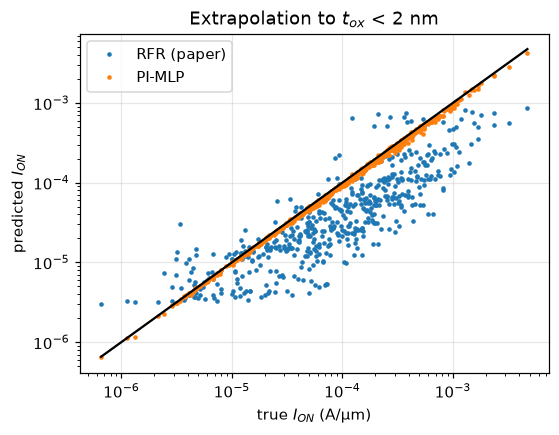

In [7]:
# --- train on thick oxide, test on thin oxide ---
inside, outside = ds4[ds4.t_ox >= 2.0], ds4[ds4.t_ox < 2.0]
print("train curves:", inside.curve_id.nunique(), "| extrapolation curves:", outside.curve_id.nunique())
ex_rows = {}
for name in TREES:
    p, ts, tp = fit_tree(name, inside, outside)
    ex_rows[name] = score(outside, p, ts, tp)
ex_runs = run_grid(inside, outside, steps=5000)
ex_seed = pd.DataFrame({k: score(outside, v[1], v[2]) for k, v in ex_runs.items()}).T
ex_seed.index.names = ["model", "seed"]
for v in VARIANTS:
    ex_rows[v] = {**ex_seed.loc[v].mean().to_dict(), "seed_std": ex_seed.loc[v, "median_rel_err_%"].std()}
ex_table = pd.DataFrame(ex_rows).T
ex_table.to_csv("../data/nb03_extrapolation.csv")
display(ex_table[["R2_linear_%", "R2_log10_%", "median_rel_err_%", "seed_std", "I_on_err_%", "I_off_err_decades",
                  "SS_min_err_mV/dec", "non_monotonic_%"]].round(3))

fig, ax = plt.subplots(figsize=(5.5, 4))
o = outside.assign(I_rf=np.clip(fit_tree("RFR-linear (paper)", inside, outside)[0], 1e-30, None),
                   I_pi=ex_runs[("PI-MLP", 0)][1])
on = o[np.isclose(o.V_G, 0.5)]
ax.loglog(on.I_D, on.I_rf, ".", ms=4, label="RFR (paper)")
ax.loglog(on.I_D, on.I_pi, ".", ms=4, label="PI-MLP")
lim = [on.I_D.min(), on.I_D.max()]; ax.plot(lim, lim, "k-")
ax.set(xlabel="true $I_{ON}$ (A/µm)", ylabel="predicted $I_{ON}$", title="Extrapolation to $t_{ox}$ < 2 nm")
ax.legend(); fig.savefig("../figures/03_extrapolation.png", bbox_inches="tight")

### 🔎 What the extrapolation test shows
Devices with thinner oxide than anything in training:

| Model | Linear $R^2$ | Typical error | I_ON error |
|---|---|---|---|
| RFR-linear (paper) | 37.3 % | 74.7 % | 64.7 % |
| XGB-log+feat (best tree) | 59.2 % | 25.2 % | 29.1 % |
| MLP-log | 98.4 % | 8.0 % | 10.2 % |
| MLP-log+feat | 98.8 % | 4.0 % | 4.9 % |
| PI-MLP | 98.8 % | 4.0 % | 4.9 % |

* **Smooth networks can continue a trend.** Trees can only repeat values they have seen, so they fail here. Even MLP-log, with no physics help, reaches 8 %.
* **Physics features halve the error again**, but the same caveat applies: the simulator uses λ directly.
* **The penalty again makes no measurable difference.**
* This is a mild test: a smooth formula, and the same physics on both sides of the 2 nm line. Real thin-oxide devices can add effects the training data never showed.

### 📚 Block: how many simulations do we need?
**What it does:** trains on 25, 100, 400 and 1600 curves and tests on the same fixed test set as notebook 2's learning curve
(`seed=7`). The forest's numbers come from `data/learning_curve_rfr.csv`. Each MLP gets 3000 steps and 3 seeds at every size, so
small datasets are not under-trained.

**How to read it:** left to right = more simulations. Lower error is better. The shaded band runs from the best to the
worst seed. A curve further left at the same height needs fewer simulations.

**What to notice:** with TCAD at about 5 hours per 100 curves, every curve saved matters. The important number is how few curves
reach a given error.

25 curves done, 1.5 min so far


100 curves done, 3.8 min so far


400 curves done, 7.1 min so far


1600 curves done, 10.4 min so far


model,RFR-linear (paper),XGB-log,MLP-log,MLP-log+feat,PI-MLP
n,,,,,
25,450.92,92.20,11.77,5.98,6.32
100,245.68,65.02,4.34,2.18,2.14
400,126.80,35.25,3.35,1.89,1.87
1600,76.81,20.05,3.19,1.89,1.85


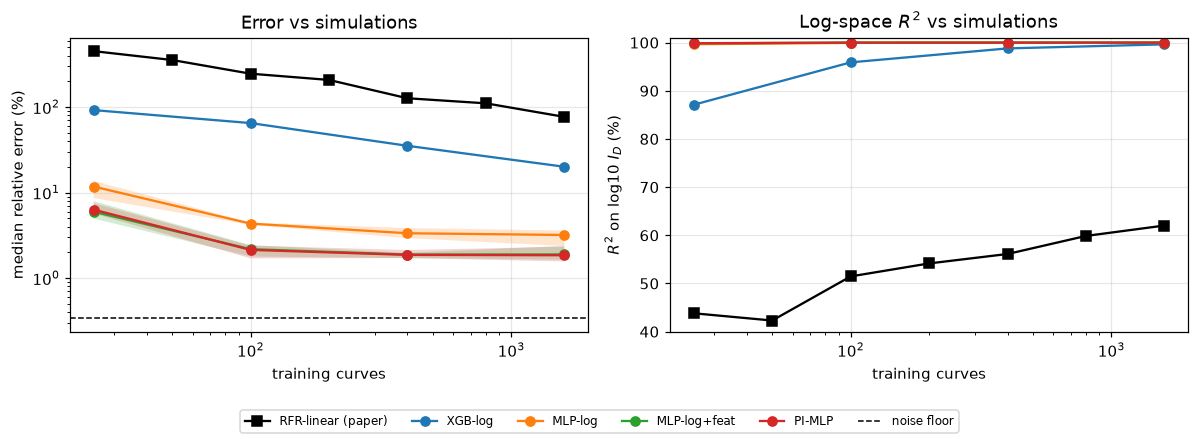

In [8]:
# --- learning curve vs the paper's model ---
_, te_fix = curve_split(ds4, 0.2, seed=7)
pool = ds4[~ds4.curve_id.isin(te_fix.curve_id)]
sizes = (25, 100, 400, 1600)
lc = []
t0 = time.perf_counter()
for n in sizes:
    ids = np.random.default_rng(0).choice(pool.curve_id.unique(), n, replace=False)
    tr_n = pool[pool.curve_id.isin(ids)]
    r = regression_report(te_fix.I_D, fit_tree("XGB-log", tr_n, te_fix)[0])
    lc.append({"model": "XGB-log", "n": n, "seed": 0, **r})
    for (v, s), res in run_grid(tr_n, te_fix, steps=3000).items():
        lc.append({"model": v, "n": n, "seed": s, **regression_report(te_fix.I_D, res[1])})
    print(f"{n} curves done, {(time.perf_counter() - t0) / 60:.1f} min so far")
lc = pd.DataFrame(lc)
lc.to_csv("../data/learning_curve_nb03.csv", index=False)
rf = pd.read_csv("../data/learning_curve_rfr.csv")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.loglog(rf["train curves"], rf["median_rel_err_%"], "ks-", label="RFR-linear (paper)")
b.semilogx(rf["train curves"], rf["R2_log10_%"], "ks-", label="RFR-linear (paper)")
for name, g in lc.groupby("model", sort=False):
    s = g.groupby("n")
    a.loglog(s["median_rel_err_%"].mean().index, s["median_rel_err_%"].mean(), "o-", label=name)
    a.fill_between(s["median_rel_err_%"].min().index, s["median_rel_err_%"].min(), s["median_rel_err_%"].max(), alpha=0.2)
    b.semilogx(s["R2_log10_%"].mean().index, s["R2_log10_%"].mean(), "o-", label=name)
a.axhline(floor["median_rel_err_%"], color="k", ls="--", lw=1, label="noise floor")
a.set(xlabel="training curves", ylabel="median relative error (%)", title="Error vs simulations")
b.set(xlabel="training curves", ylabel="$R^2$ on log10 $I_D$ (%)", title="Log-space $R^2$ vs simulations", ylim=(40, 101))
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(*a.get_legend_handles_labels(), loc="lower center", ncol=6, fontsize=8)
fig.savefig("../figures/03_learning_curve.png", bbox_inches="tight")
lc_table = lc.pivot_table(index="n", columns="model", values="median_rel_err_%", sort=False).round(2)
lc_table.insert(0, "RFR-linear (paper)", rf.set_index("train curves")["median_rel_err_%"].round(2))
lc_table

### 🔎 What the learning curve shows
* **Far fewer simulations:** PI-MLP trained on **25 curves** (6.3 % error) beats the paper's forest on **1600 curves** (76.8 %) and XGB-log on 1600 curves (20.1 %).
* **Fair comparison:** the forest's target is linear, so it has a built-in handicap on this metric. XGB-log is the fairer tree baseline.
* **Physics features matter most at small sizes in absolute terms:** at 25 curves the error is 11.8 % for MLP-log and about 6 % with features.
* **The penalty doesn't help with little data either:** 6.3 % with it, 6.0 % without, at 25 curves.
* **The MLP curves flatten near 1.9 % from 400 curves on.** The main run reached 1.0 % with 5000 steps, so this is probably the 3000-step budget here rather than a data limit. We did not test that directly.

### 💾 Block: save the best neural model
**What it does:** picks the MLP variant with the lowest average median error and saves its **seed 0** run to `models/`, then
reloads it to check the file works. We always save seed 0, so we aren't cherry-picking the luckiest run on the test set.

**How to read it:** the last line should say the reloaded model matches.

**What to notice:** notebooks 04 and 05 can load this file instead of training again.

In [9]:
# --- save and check ---
best = table.loc[list(VARIANTS), "median_rel_err_%"].idxmin()
model = runs[(best, 0)][0]
os.makedirs("../models", exist_ok=True)
joblib.dump(model, "../models/best_surrogate_ds4.joblib")
again = joblib.load("../models/best_surrogate_ds4.joblib")
same = np.allclose(again.predict_log(X_of(test)), model.predict_log(X_of(test)))
print(f"saved {best} (seed 0) | reloaded model matches: {same}")

saved PI-MLP (seed 0) | reloaded model matches: True


### 🏁 Conclusions
1. The paper's failures from notebook 2 are fixed: I_OFF, V_th, SS and smooth curves are all recovered, and the typical error falls from 62 % to about 1 %.
2. The log target and the smooth network do most of the work. Physics features halve the remaining error, but they come from the simulator's own formulas.
3. The monotonicity penalty gave no measurable benefit in any of the three tests, and it makes training slower. PI-MLP was saved as "best" by a margin smaller than the seed spread, so MLP-log+feat is equally good.
4. Everything here is measured on analytical data with 0.5 % noise. The next real test of these claims would be TCAD data.

**Next:** notebook 04 adds uncertainty (deep ensembles) and active learning on dataset 5, which also varies $V_D$ and temperature.